Dataset shape: (569, 30)
Number of features: 30
Scaled features shape: (569, 30)

--- Explained Variance Ratios ---
PC1: 44.27 %
PC2: 18.97 %
Cumulative: 63.24 %
Reduced dataset shape: (569, 2)


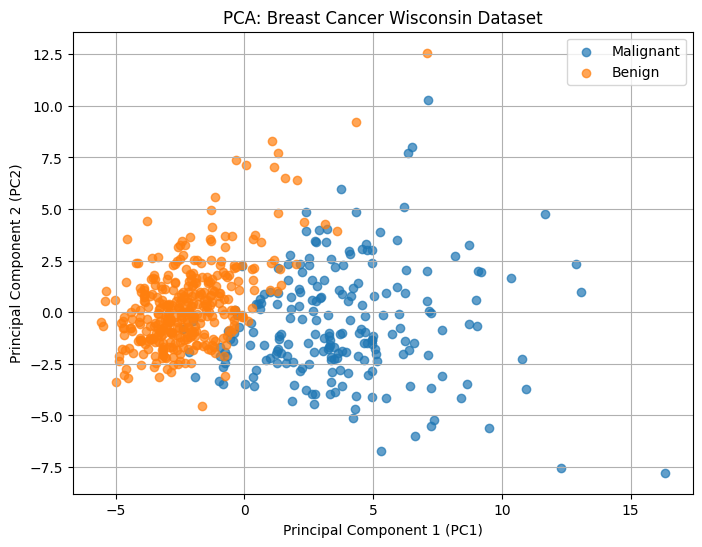


--- Classification Results ---
Test Accuracy: 93.86 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.92      0.99      0.95        72
   Malignant       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Task 1: Load dataset and scale 30 features
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target.map({0: "Malignant", 1: "Benign"})

# Standardize the 30 continuous features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Scaled features shape:", X_scaled.shape)

# Task 2: Apply PCA to reduce 30 features to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\n--- Explained Variance Ratios ---")
print("PC1:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC2:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")
print("Cumulative:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

print("Reduced dataset shape:", X_pca.shape)

# Task 3: Plot PC1 vs PC2
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[y == "Malignant", 0],
    X_pca[y == "Malignant", 1],
    label="Malignant",
    alpha=0.7
)

plt.scatter(
    X_pca[y == "Benign", 0],
    X_pca[y == "Benign", 1],
    label="Benign",
    alpha=0.7
)

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA: Breast Cancer Wisconsin Dataset")
plt.legend()
plt.grid(True)
plt.show()

# Task 4: Train Logistic Regression classifier
X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\n--- Classification Results ---")
print("Test Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))
